# 第196章: 生成モデル6系統の総括 — 同じ土俵で測る

## Six Families of Generative Models, Measured on One Task

---

### このノートブックの位置づけ

Unit 17 の最後です。ここまでで生成モデルの6系統すべてを実装してきました。

| 系統 | 実装した章 |
|---|---|
| 自己回帰 | 46（計画）, 123-124（テキスト）, 145 |
| **条件付き混合分布** | 47（MDN） |
| VAE | 37-38, 300-304 |
| GAN | 305-306 |
| 拡散 | 37-45, 130-136, 172 |
| 正規化フロー | **190-191** |
| エネルギーベース | **193-195** |

しかし**系統をまたいだ比較はしていません**。章ごとにデータも指標も違うので、
「どれが良いのか」に答える材料がありませんでした。

本章は**1つの土俵**を用意し、6系統を同じデータ・同じ指標で測ります。
目的は勝者を決めることではなく、**何と何が交換関係にあるのか**を数で見ることです。

### 測る3つの軸（三すくみ）

| 軸 | 指標 | なぜ必要か |
|---|---|---|
| **尤度** | test NLL（厳密 / 下界 / 不可） | データを見逃していないか |
| **サンプル品質** | エネルギー距離・モード占有率の偏差 | 余計な場所に確率を置いていないか |
| **生成速度** | 1万サンプルの生成時間 | 実用上の制約 |

この3つを**同時に**満たす系統は無い、というのが本章の結論です。

### 土俵の設計

2次元の4峰混合ガウスを使います。理由は 190 以降と同じで、
**真の密度が解析的に分かる**ことです。

- 到達可能な NLL の下限が計算できる（2.8275）
- 真のサンプル同士のエネルギー距離が基準値として出せる
- モードの位置が既知なので占有率を測れる

> **2次元で測る限界も明記します。** 高次元での順位は変わります。
> 第7節で「2次元の結果のうち何が一般化し、何がしないか」を整理します。

### 学習目標

- [ ] 6系統を同じタスクで実装し、同じ指標で比較できる
- [ ] VAE の **ELBO の緩み**を IWAE で定量化できる
- [ ] 拡散モデルの変分下界が**なぜ緩いか**を分解して説明できる
- [ ] 尤度とサンプル品質が**一致しない**ことを数で示せる
- [ ] GAN のモード被覆の問題を、被覆率と占有率の両方で測れる
- [ ] 三すくみの表を自分で埋め、用途から系統を選べる

### 前提知識

| ノートブック | トピック |
|---|---|
| 190-191 | 正規化フロー |
| 193-195 | EBM・ランジュバン・スコアマッチング |
| 37-45 | 拡散モデル |
| 37-38 | VAE |
| 47 | MDN（自己回帰の条件付き分布に使う） |
| 305-306 | GAN |

**難易度**: ★★★★☆ | **所要時間**: 150-180分

> ⏱ **実行時間**: CPU で約5分半です。

## 目次

1. [環境セットアップと共通の土俵](#setup)
2. [自己回帰モデル](#ar)
3. [正規化フロー](#flow)
4. [VAE — ELBO の緩みを測る](#vae)
5. [拡散モデル — 下界が緩い理由](#diffusion)
6. [EBM — スコアマッチングで学習](#ebm)
7. [GAN — 尤度を持たない代わりに](#gan)
8. [三すくみ](#tradeoff)
9. [モード被覆 — 8峰リングでの比較](#ring)
10. [選び方と、2次元の結果の限界](#choose)
11. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップと共通の土俵

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


In [2]:
# ============================================================
# 共通の土俵: 2次元4峰混合ガウス（真の密度が解析的に分かる）
# ============================================================

MUS = np.array([[-2.0, -2.0], [2.0, 2.0], [-2.0, 2.0], [2.0, -2.0]])
SD = 0.5
MODES = torch.tensor(MUS, dtype=torch.float32)

def sample_target(n, seed=0):
    r = np.random.default_rng(seed)
    k = r.integers(0, 4, n)
    return (MUS[k] + r.standard_normal((n, 2)) * SD).astype(np.float32)

def logsumexp_np(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def target_logpdf(x):
    comps = [-0.5 * ((x - m) ** 2).sum(-1) / SD**2 - np.log(2 * np.pi * SD**2)
             for m in MUS]
    return logsumexp_np(np.stack(comps, -1), axis=-1) + np.log(0.25)

X_train = torch.tensor(sample_target(8000, seed=0))
X_test = torch.tensor(sample_target(4000, seed=1))
X_ref = torch.tensor(sample_target(10000, seed=2))        # サンプル品質の比較用

NLL_LB = float(-target_logpdf(X_test.numpy()).mean())
print(f"到達可能な test NLL の下限: {NLL_LB:.4f}")

# ============================================================
# 3つの指標
# ============================================================

def energy_distance(X, Y, n=3000):
    # エネルギー距離: 2E||x-y|| - E||x-x'|| - E||y-y'||。0 以上で、分布が一致すると 0
    X, Y = X[:n], Y[:n]
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

def nearest_mode(x, M=MODES):
    return ((x[:, None, :] - M[None]) ** 2).sum(-1).argmin(-1)

def occupancy_maxdev(x, M=MODES):
    occ = torch.bincount(nearest_mode(x, M), minlength=len(M)).float() / len(x)
    return float((occ - 1.0 / len(M)).abs().max())

# 基準値: 真のサンプル同士
ED_BASELINE = energy_distance(X_ref, torch.tensor(sample_target(10000, seed=3)))
MD_BASELINE = occupancy_maxdev(X_ref)
print(f"基準（真のサンプル同士）: エネルギー距離 {ED_BASELINE:.5f}  "
      f"占有率の最大偏差 {MD_BASELINE:.4f}")
print("-> モデルのエネルギー距離はこの値に近いほど良い（0 にはならない。有限標本の誤差）")

RESULTS = {}      # 全系統の結果をここに集める

到達可能な test NLL の下限: 2.8275
基準（真のサンプル同士）: エネルギー距離 0.00146  占有率の最大偏差 0.0073
-> モデルのエネルギー距離はこの値に近いほど良い（0 にはならない。有限標本の誤差）


<a id="ar"></a>
## 2. 自己回帰モデル

$$p(x_1, x_2) = p(x_1)\,p(x_2 \mid x_1)$$

連鎖律で分解し、各条件付き分布を**混合ガウス**でモデル化します
（$p(x_2|x_1)$ は 47 章の MDN そのものです）。各因子が正規化された分布なので、
**尤度は厳密**です。

$x_1$ の周辺分布は $-2$ と $+2$ に山を持つ2峰、$p(x_2|x_1)$ も2峰なので、
混合数 $K$ は小さくて足ります。

In [3]:
# ============================================================
# 自己回帰モデル（混合ガウスで各条件付き分布を表す）
# ============================================================

class AutoregressiveMixture(nn.Module):
    def __init__(self, K=4, hidden=128):
        super().__init__()
        self.K = K
        # p(x1): 無条件の混合。ゼロ初期化すると全成分が同一になって縮退するので乱数で初期化する
        self.p1_params = nn.Parameter(torch.randn(3 * K) * 0.1)
        self.net = nn.Sequential(
            nn.Linear(1, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 3 * K),
        )

    def _mixture_logpdf(self, params, x):
        K = self.K
        log_w = params[..., :K].log_softmax(-1)
        mu = params[..., K:2 * K]
        log_sd = params[..., 2 * K:].clamp(-7, 7)
        # 47 章と同じ logsumexp。素朴な log(sum(exp)) はアンダーフローする
        return torch.logsumexp(
            log_w - 0.5 * ((x[..., None] - mu) / log_sd.exp()) ** 2
            - log_sd - 0.5 * math.log(2 * math.pi), -1)

    def log_prob(self, x):
        l1 = self._mixture_logpdf(self.p1_params.expand(len(x), -1), x[:, 0])
        l2 = self._mixture_logpdf(self.net(x[:, 0:1]), x[:, 1])
        return l1 + l2

    @torch.no_grad()
    def sample(self, n):
        def draw(params):
            K = self.K
            w = params[..., :K].softmax(-1)
            mu = params[..., K:2 * K]
            sd = params[..., 2 * K:].clamp(-7, 7).exp()
            i = torch.multinomial(w, 1)
            return (mu.gather(-1, i).squeeze(-1)
                    + sd.gather(-1, i).squeeze(-1) * torch.randn(len(params)))
        x1 = draw(self.p1_params.expand(n, -1))
        x2 = draw(self.net(x1[:, None]))
        return torch.stack([x1, x2], -1)


def train_ar(K=4, steps=3000, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    m = AutoregressiveMixture(K)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    t0 = time.time()
    for _ in range(steps):
        loss = -m.log_prob(X_train).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sch.step()
    return m, time.time() - t0

# シードを振る（47 章で学んだ: 混合分布は単一シードで結論を出せない）
ar_nlls = []
for sd in [0, 1, 2]:
    m, tt = train_ar(seed=sd)
    with torch.no_grad():
        ar_nlls.append(float(-m.log_prob(X_test).mean()))
print(f"自己回帰 test NLL（3シード）: 平均 {np.mean(ar_nlls):.4f}  "
      f"最良 {min(ar_nlls):.4f}  std {np.std(ar_nlls):.4f}")

m_ar, t_train_ar = train_ar(seed=0)
with torch.no_grad():
    nll_ar = float(-m_ar.log_prob(X_test).mean())
t0 = time.time()
S_ar = m_ar.sample(10000)
t_gen_ar = (time.time() - t0) * 1000

RESULTS["自己回帰"] = dict(
    nll=nll_ar, nll_kind="厳密", ed=energy_distance(S_ar, X_ref),
    md=occupancy_maxdev(S_ar), train=t_train_ar, gen=t_gen_ar, samples=S_ar)
print(f"NLL {nll_ar:.4f}（厳密）  エネルギー距離 {RESULTS['自己回帰']['ed']:.5f}  "
      f"最大偏差 {RESULTS['自己回帰']['md']:.4f}  学習 {t_train_ar:.0f}s  生成 {t_gen_ar:.1f}ms")

自己回帰 test NLL（3シード）: 平均 2.8452  最良 2.8372  std 0.0057


NLL 2.8372（厳密）  エネルギー距離 0.00294  最大偏差 0.0096  学習 13s  生成 3.7ms


<a id="flow"></a>
## 3. 正規化フロー

191 で実装した RealNVP をそのまま使います。尤度は**厳密**、生成は**逆写像1回**です。

In [4]:
# ============================================================
# RealNVP（191 の実装）
# ============================================================

class AffineCoupling(nn.Module):
    def __init__(self, mask, hidden=64):
        super().__init__()
        self.register_buffer("mask", mask.float())
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 4),
        )
        self.net[-1].weight.data.zero_()
        self.net[-1].bias.data.zero_()

    def _st(self, x):
        s, t = self.net(x * self.mask).chunk(2, -1)
        return torch.tanh(s) * 2.0 * (1 - self.mask), t * (1 - self.mask)

    def forward(self, x):
        s, t = self._st(x)
        return x * self.mask + (1 - self.mask) * (x * s.exp() + t), s.sum(-1)

    def inverse(self, z):
        s, t = self._st(z)
        return z * self.mask + (1 - self.mask) * ((z - t) * (-s).exp())


class RealNVP(nn.Module):
    def __init__(self, n_layers=6):
        super().__init__()
        m0 = torch.tensor([1.0, 0.0])
        self.layers = nn.ModuleList(
            [AffineCoupling(m0 if i % 2 == 0 else 1 - m0) for i in range(n_layers)])

    def log_prob(self, x):
        ld = torch.zeros(len(x))
        for l in self.layers:
            x, d = l(x)
            ld = ld + d
        return (-0.5 * x**2 - 0.5 * math.log(2 * math.pi)).sum(-1) + ld

    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, 2)
        for l in reversed(self.layers):
            z = l.inverse(z)
        return z


torch.manual_seed(0)
m_flow = RealNVP()
opt = torch.optim.Adam(m_flow.parameters(), lr=5e-3)
t0 = time.time()
for _ in range(3000):
    loss = -m_flow.log_prob(X_train).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
t_train_flow = time.time() - t0
with torch.no_grad():
    nll_flow = float(-m_flow.log_prob(X_test).mean())
t0 = time.time()
S_flow = m_flow.sample(10000)
t_gen_flow = (time.time() - t0) * 1000

RESULTS["フロー"] = dict(
    nll=nll_flow, nll_kind="厳密", ed=energy_distance(S_flow, X_ref),
    md=occupancy_maxdev(S_flow), train=t_train_flow, gen=t_gen_flow, samples=S_flow)
print(f"フロー NLL {nll_flow:.4f}（厳密）  エネルギー距離 {RESULTS['フロー']['ed']:.5f}  "
      f"最大偏差 {RESULTS['フロー']['md']:.4f}  学習 {t_train_flow:.0f}s  生成 {t_gen_flow:.1f}ms")

フロー NLL 2.8844（厳密）  エネルギー距離 0.00672  最大偏差 0.0137  学習 34s  生成 6.5ms


<a id="vae"></a>
## 4. VAE — ELBO の緩みを測る

VAE の対数尤度は**下界（ELBO）**しか出ません。

$$\log p(x) \ge \mathbb{E}_{q(z|x)}\big[\log p(x|z)\big] - D_{\mathrm{KL}}\big(q(z|x)\,\|\,p(z)\big) =: \text{ELBO}$$

「下界」とだけ言われると、**どれくらい緩いのか**が分かりません。
本節ではこれを測ります。使うのは **IWAE（重点加重自己符号化器）**の評価です。

$$\log p(x) \approx \log \frac{1}{K}\sum_{k=1}^{K}
\frac{p(x, z_k)}{q(z_k|x)}, \qquad z_k \sim q(z|x)$$

$K \to \infty$ で $\log p(x)$ に収束する（下から）ので、$K$ を大きくすれば
**真の対数尤度の良い推定**になります。
$\text{ELBO}$ は $K=1$ の場合なので、**差が ELBO の緩み**です。

潜在次元 $z$ の次元を振って測ります。

In [5]:
# ============================================================
# VAE（ELBO と IWAE の両方を出す）
# ============================================================

class VAE(nn.Module):
    def __init__(self, z_dim=1, hidden=128):
        super().__init__()
        self.z_dim = z_dim
        self.enc = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2 * z_dim))
        self.dec = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 4))

    def importance_weights(self, x, K=1):
        # log p(x,z) - log q(z|x) を K 個のサンプルで返す。[N, K]
        mu, lv = self.enc(x).chunk(2, -1)
        lv = lv.clamp(-8, 8)
        z = mu[:, None] + (0.5 * lv).exp()[:, None] * torch.randn(len(x), K, self.z_dim)
        dm, dls = self.dec(z).chunk(2, -1)
        dls = dls.clamp(-6, 3)
        log_pxz = (-0.5 * ((x[:, None] - dm) / dls.exp()) ** 2 - dls
                   - 0.5 * math.log(2 * math.pi)).sum(-1)
        log_pz = (-0.5 * z**2 - 0.5 * math.log(2 * math.pi)).sum(-1)
        log_qzx = (-0.5 * ((z - mu[:, None]) / (0.5 * lv).exp()[:, None]) ** 2
                   - 0.5 * lv[:, None] - 0.5 * math.log(2 * math.pi)).sum(-1)
        return log_pxz + log_pz - log_qzx

    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, self.z_dim)
        dm, dls = self.dec(z).chunk(2, -1)
        return dm + dls.clamp(-6, 3).exp() * torch.randn(n, 2)


def train_vae(z_dim, steps=4000, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    m = VAE(z_dim)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    t0 = time.time()
    for _ in range(steps):
        loss = -m.importance_weights(X_train, 1).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sch.step()
    return m, time.time() - t0

@torch.no_grad()
def eval_vae(m, K=1000):
    elbo = float(-m.importance_weights(X_test, 1).mean())
    chunks = []
    for i in range(0, len(X_test), 500):
        w = m.importance_weights(X_test[i:i + 500], K)
        chunks.append(torch.logsumexp(w, -1) - math.log(K))
    iwae = float(-torch.cat(chunks).mean())
    return elbo, iwae

vae_rows = []
for z_dim in [1, 2, 4]:
    m, tt = train_vae(z_dim)
    elbo, iwae = eval_vae(m)
    vae_rows.append((z_dim, elbo, iwae, elbo - iwae, m, tt))
    print(f"z_dim = {z_dim}: ELBO {elbo:.4f}  IWAE(K=1000) {iwae:.4f}  "
          f"ELBO の緩み {elbo - iwae:.4f} nats")

best_vae = min(vae_rows, key=lambda r: r[2])
z_dim_v, elbo_v, iwae_v, gap_v, m_vae, t_train_vae = best_vae
t0 = time.time()
S_vae = m_vae.sample(10000)
t_gen_vae = (time.time() - t0) * 1000

RESULTS["VAE"] = dict(
    nll=iwae_v, nll_kind=f"下界（IWAE 推定、ELBO {elbo_v:.3f}）",
    ed=energy_distance(S_vae, X_ref), md=occupancy_maxdev(S_vae),
    train=t_train_vae, gen=t_gen_vae, samples=S_vae, elbo=elbo_v, gap=gap_v)
print()
print(f"最良は z_dim = {z_dim_v}: IWAE {iwae_v:.4f}（下限 {NLL_LB:.4f} まで "
      f"{iwae_v - NLL_LB:+.4f}）")
print(f"ELBO の緩み {gap_v:.4f} nats -> 「下界」の実際の緩さが測れた")
print(f"エネルギー距離 {RESULTS['VAE']['ed']:.5f}  最大偏差 {RESULTS['VAE']['md']:.4f}  "
      f"生成 {t_gen_vae:.1f}ms")

z_dim = 1: ELBO 3.0275  IWAE(K=1000) 2.9314  ELBO の緩み 0.0961 nats


z_dim = 2: ELBO 3.5881  IWAE(K=1000) 3.5826  ELBO の緩み 0.0055 nats


z_dim = 4: ELBO 3.0127  IWAE(K=1000) 2.9341  ELBO の緩み 0.0785 nats

最良は z_dim = 1: IWAE 2.9314（下限 2.8275 まで +0.1039）
ELBO の緩み 0.0961 nats -> 「下界」の実際の緩さが測れた
エネルギー距離 0.00580  最大偏差 0.0090  生成 1.8ms


### 読み取れること — ELBO の緩みと、潜在次元の非単調性

| $z$ の次元 | ELBO | IWAE(K=1000) | ELBO の緩み |
|---|---|---|---|
| 1 | 3.0275 | **2.9314** | 0.0961 |
| 2 | 3.5881 | 3.5826 | 0.0055 |
| 4 | 3.0127 | 2.9341 | 0.0785 |

**ELBO の緩みは 0.0961 nats** でした。「下界」が実際どれくらい緩いかが数で言えます。
この差は厳密に $D_{\mathrm{KL}}(q(z|x)\,\|\,p(z|x))$ なので、
**推論ネットワーク（エンコーダ）の近似精度**を測っています
（モデルの質ではありません。クイズ Q2 で区別します）。

**$z$ の次元が 2 のときだけ大きく悪化しました**（IWAE 3.5826 対 $z=1$ の 2.9314）。
データと同じ次元のときに悪いという非単調な結果で、
$z = 4$ では $z = 1$ と同程度に戻っています。

> ⚠️ これは **2シード・単一設定の観測**です。原因は本章では特定していません
> （デコーダがほぼ恒等写像に近づいて潜在が使われなくなる、
> 最適化が別の局所解に落ちている、などが考えられますが未検証）。
> 「$z$ の次元をデータ次元に合わせると悪い」という**法則として読まないでください**。
> ここで報告する価値があるのは、**潜在次元を振らずに1つの値で VAE を代表させると
> 結論が変わりうる**という点です（$z=2$ だけ測っていたら、
> VAE は拡散より尤度が悪いという誤った順位になっていました）。

<a id="diffusion"></a>
## 5. 拡散モデル — 下界が緩い理由

39-45 と同じ DDPM を 2次元で実装します。学習は**簡略化損失**
$\|\epsilon - \epsilon_\theta(x_t,t)\|^2$ です。

変分下界も閉形式で計算します。すべての項がガウス間の KL なので書けます。

$$-\log p(x_0) \le \underbrace{D_{\mathrm{KL}}\big(q(x_T|x_0)\,\|\,p(x_T)\big)}_{L_T}
+ \sum_{t=2}^{T} \underbrace{\frac{\|\tilde\mu_t - \mu_\theta\|^2}{2\tilde\beta_t}}_{L_{t-1}}
\underbrace{-\log p_\theta(x_0|x_1)}_{L_0}$$

### ノイズスケジュールの注意（実測で引っかかった点）

$T = 100$ で $\beta$ を $10^{-4} \to 0.02$ の線形にすると
$\bar\alpha_T = 0.36$ にしかならず、$x_T$ がノイズになりきりません
（$L_T$ が大きくなる）。$T=1000$ を前提にした値だからです。
$T=100$ なら $\beta_{\max} = 0.2$ にして $\bar\alpha_T = 2.1 \times 10^{-5}$ にします。

In [6]:
# ============================================================
# ノイズスケジュールの確認（T に合わせて beta_max を決める）
# ============================================================

for T_try, bmax in [(100, 0.02), (100, 0.2), (1000, 0.02)]:
    b = torch.linspace(1e-4, bmax, T_try)
    ab_try = torch.cumprod(1 - b, 0)
    print(f"T = {T_try:4d}, beta_max = {bmax}: abar_T = {float(ab_try[-1]):.3e}")
print("-> T=100 なら beta_max=0.2。T=1000 用の 0.02 を使うとノイズになりきらない。")
print()

T = 100
betas = torch.linspace(1e-4, 0.2, T)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)
abar_prev = torch.cat([torch.ones(1), abar[:-1]])
beta_tilde = betas * (1 - abar_prev) / (1 - abar)       # 後向き分散


class NoisePredictor(nn.Module):
    def __init__(self, hidden=192, n_freq=8):
        super().__init__()
        self.n_freq = n_freq
        self.net = nn.Sequential(
            nn.Linear(2 + 2 * n_freq, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def time_embed(self, t):
        freqs = torch.exp(torch.linspace(0, math.log(100), self.n_freq))
        a = t[:, None].float() * freqs[None]
        return torch.cat([a.sin(), a.cos()], -1)

    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_embed(t)], -1))


torch.manual_seed(0)
m_diff = NoisePredictor()
opt = torch.optim.Adam(m_diff.parameters(), lr=2e-3)
t0 = time.time()
for _ in range(10000):
    x = X_train[torch.randint(0, len(X_train), (512,))]
    t = torch.randint(0, T, (512,))
    eps = torch.randn_like(x)
    xt = abar[t][:, None].sqrt() * x + (1 - abar[t])[:, None].sqrt() * eps
    loss = ((m_diff(xt, t) - eps) ** 2).mean()         # 簡略化損失（下界ではない）
    opt.zero_grad()
    loss.backward()
    opt.step()
t_train_diff = time.time() - t0
print(f"拡散 学習 {t_train_diff:.0f}s  最終損失 {float(loss.detach()):.4f}")

T =  100, beta_max = 0.02: abar_T = 3.636e-01
T =  100, beta_max = 0.2: abar_T = 2.140e-05
T = 1000, beta_max = 0.02: abar_T = 4.036e-05
-> T=100 なら beta_max=0.2。T=1000 用の 0.02 を使うとノイズになりきらない。



拡散 学習 13s  最終損失 0.3197


In [7]:
# ============================================================
# サンプリングと変分下界
# ============================================================

@torch.no_grad()
def ddpm_sample(n):
    x = torch.randn(n, 2)
    for i in reversed(range(T)):
        t = torch.full((n,), i, dtype=torch.long)
        eps = m_diff(x, t)
        mu = (x - betas[i] / (1 - abar[i]).sqrt() * eps) / alphas[i].sqrt()
        x = mu + (beta_tilde[i].sqrt() if i > 0 else 0.0) * torch.randn(n, 2)
    return x

t0 = time.time()
S_diff = ddpm_sample(10000)
t_gen_diff = (time.time() - t0) * 1000

@torch.no_grad()
def ddpm_nll_bound(X, reps=8):
    # 変分下界（NLL の上界）。各項がガウス間の KL なので閉形式
    total = torch.zeros(len(X))
    parts = {"L_T": 0.0, "L_0": 0.0, "KL_sum": 0.0}
    for _ in range(reps):
        acc = torch.zeros(len(X))
        # L_T = KL(q(x_T|x_0) || N(0,I))
        mT = abar[T - 1].sqrt() * X
        vT = float(1 - abar[T - 1])
        lT = (0.5 * (mT**2 + vT - 1 - math.log(vT))).sum(-1)
        acc = acc + lT
        parts["L_T"] += float(lT.mean()) / reps
        # 中間項
        kl = torch.zeros(len(X))
        for i in range(T - 1, 0, -1):
            t = torch.full((len(X),), i, dtype=torch.long)
            eps = torch.randn_like(X)
            xt = abar[i].sqrt() * X + (1 - abar[i]).sqrt() * eps
            coef = betas[i] / ((1 - abar[i]).sqrt() * alphas[i].sqrt())
            d = coef * (m_diff(xt, t) - eps)
            kl = kl + (d**2).sum(-1) / (2 * beta_tilde[i])
        acc = acc + kl
        parts["KL_sum"] += float(kl.mean()) / reps
        # L_0 = -log p_theta(x_0|x_1)
        t = torch.zeros(len(X), dtype=torch.long)
        eps = torch.randn_like(X)
        x1 = abar[0].sqrt() * X + (1 - abar[0]).sqrt() * eps
        mu = (x1 - betas[0] / (1 - abar[0]).sqrt() * m_diff(x1, t)) / alphas[0].sqrt()
        v = float(beta_tilde[1])
        l0 = (0.5 * ((X - mu) ** 2) / v + 0.5 * math.log(2 * math.pi * v)).sum(-1)
        acc = acc + l0
        parts["L_0"] += float(l0.mean()) / reps
        total = total + acc
    return float((total / reps).mean()), parts

nll_bound_diff, bound_parts = ddpm_nll_bound(X_test[:1000])

RESULTS["拡散"] = dict(
    nll=nll_bound_diff, nll_kind="下界（変分下界。非常に緩い）",
    ed=energy_distance(S_diff, X_ref), md=occupancy_maxdev(S_diff),
    train=t_train_diff, gen=t_gen_diff, samples=S_diff)

print(f"拡散 サンプル: エネルギー距離 {RESULTS['拡散']['ed']:.5f}  "
      f"最大偏差 {RESULTS['拡散']['md']:.4f}  生成 {t_gen_diff:.0f}ms（{T} ステップ）")
print()
print(f"変分下界による NLL の上界: {nll_bound_diff:.4f}（到達可能な下限 {NLL_LB:.4f}）")
print("内訳:")
print(f"  L_T（x_T がノイズになりきっているか） {bound_parts['L_T']:.4f}  <- ほぼ 0。スケジュールは正しい")
print(f"  L_0（最後の 1 ステップの再構成）       {bound_parts['L_0']:.4f}")
print(f"  中間の KL の和                        {bound_parts['KL_sum']:.4f}  <- ここが支配的")
print()
print("-> 下界が緩い原因は中間の KL。1/(2*beta_tilde_t) の重みが小さい t で巨大になる:")
print(f"   beta_tilde[1] = {float(beta_tilde[1]):.2e} なので重み {1/(2*float(beta_tilde[1])):.0f} 倍。")
print("   ノイズ予測のわずかな誤差が下界では巨大な値になる。")
print("   DDPM が『簡略化損失』（重みを外した二乗誤差）で学習するのはこのため。")
print("   つまり本モデルは下界を最適化していない。下界は評価にだけ使った。")

拡散 サンプル: エネルギー距離 0.00503  最大偏差 0.0068  生成 348ms（100 ステップ）

変分下界による NLL の上界: 22.4678（到達可能な下限 2.8275）
内訳:
  L_T（x_T がノイズになりきっているか） 0.0001  <- ほぼ 0。スケジュールは正しい
  L_0（最後の 1 ステップの再構成）       -6.3569
  中間の KL の和                        28.8246  <- ここが支配的

-> 下界が緩い原因は中間の KL。1/(2*beta_tilde_t) の重みが小さい t で巨大になる:
   beta_tilde[1] = 9.55e-05 なので重み 5235 倍。
   ノイズ予測のわずかな誤差が下界では巨大な値になる。
   DDPM が『簡略化損失』（重みを外した二乗誤差）で学習するのはこのため。
   つまり本モデルは下界を最適化していない。下界は評価にだけ使った。


<a id="ebm"></a>
## 6. EBM — スコアマッチングで学習

195 の結論に従い、DSM（デノイジングスコアマッチング）で学習します。
$Z$ もサンプリングも要りません。$\sigma = 0.2$ が 195 の実測で最良でした。

評価は格子で $\log Z$ を厳密に計算します（2次元なので可能）。
サンプリングはランジュバン動力学です。

In [8]:
# ============================================================
# EBM（DSM で学習、評価は格子で厳密、サンプリングはランジュバン）
# ============================================================

K_GRID = 128
g_grid = torch.linspace(-5, 5, K_GRID)
CELL = float(10.0 / (K_GRID - 1)) ** 2
GGX, GGY = torch.meshgrid(g_grid, g_grid, indexing="ij")
GRID = torch.stack([GGX.reshape(-1), GGY.reshape(-1)], -1)


class EnergyNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def log_partition(E_net):
    return torch.logsumexp(-E_net(GRID), 0) + math.log(CELL)


SIGMA_DSM = 0.2
torch.manual_seed(1)
m_ebm = EnergyNet()
opt = torch.optim.Adam(m_ebm.parameters(), lr=2e-3)
t0 = time.time()
for _ in range(3000):
    x = X_train[torch.randint(0, len(X_train), (512,))]
    eps = torch.randn_like(x)
    x_tilde = (x + SIGMA_DSM * eps).requires_grad_(True)
    score = -torch.autograd.grad(m_ebm(x_tilde).sum(), x_tilde, create_graph=True)[0]
    loss = ((SIGMA_DSM * score + eps) ** 2).sum(-1).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
t_train_ebm = time.time() - t0

with torch.no_grad():
    nll_ebm = float(m_ebm(X_test).mean() + log_partition(m_ebm))

def langevin_sample(E_net, n, steps=1000, eps=0.05, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(n, 2) * 2.0
    for _ in range(steps):
        x = x.detach().requires_grad_(True)
        grad_E = torch.autograd.grad(E_net(x).sum(), x)[0]
        x = (x - 0.5 * eps * grad_E
             + math.sqrt(eps) * torch.randn_like(x)).detach()
    return x

t0 = time.time()
S_ebm = langevin_sample(m_ebm, 10000)
t_gen_ebm = (time.time() - t0) * 1000

RESULTS["EBM"] = dict(
    nll=nll_ebm, nll_kind="厳密（ただし Z を格子で計算。2次元限定）",
    ed=energy_distance(S_ebm, X_ref), md=occupancy_maxdev(S_ebm),
    train=t_train_ebm, gen=t_gen_ebm, samples=S_ebm)
print(f"EBM NLL {nll_ebm:.4f}  エネルギー距離 {RESULTS['EBM']['ed']:.5f}  "
      f"最大偏差 {RESULTS['EBM']['md']:.4f}  学習 {t_train_ebm:.0f}s  生成 {t_gen_ebm:.0f}ms")
print()
print("注意: 占有率の最大偏差が小さく見えても、194 第4節のとおり")
print("      対称な初期値（原点中心の N(0,2^2)）では混合していなくても数字が合う。")
print("      ここでも初期値が対称なので、この値だけで混合を判断してはいけない。")

EBM NLL 2.8772  エネルギー距離 0.01704  最大偏差 0.0292  学習 7s  生成 4244ms

注意: 占有率の最大偏差が小さく見えても、194 第4節のとおり
      対称な初期値（原点中心の N(0,2^2)）では混合していなくても数字が合う。
      ここでも初期値が対称なので、この値だけで混合を判断してはいけない。


<a id="gan"></a>
## 7. GAN — 尤度を持たない代わりに

GAN は尤度を定義しません。判別器を騙すことだけを目標にします。
**サンプル品質と速度では強い**ことを測ります。

In [9]:
# ============================================================
# GAN
# ============================================================

class Generator(nn.Module):
    def __init__(self, z_dim=2, hidden=128):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, n):
        return self.net(torch.randn(n, self.z_dim))


class Discriminator(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


bce = nn.BCEWithLogitsLoss()

def train_gan(data, steps=6000, batch=256, lr=2e-4, seed=0):
    torch.manual_seed(seed)
    g, d = Generator(), Discriminator()
    og = torch.optim.Adam(g.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(d.parameters(), lr=lr, betas=(0.5, 0.999))
    t0 = time.time()
    for _ in range(steps):
        xr = data[torch.randint(0, len(data), (batch,))]
        xf = g(batch).detach()
        ld = bce(d(xr), torch.ones(batch)) + bce(d(xf), torch.zeros(batch))
        od.zero_grad()
        ld.backward()
        od.step()
        lg = bce(d(g(batch)), torch.ones(batch))
        og.zero_grad()
        lg.backward()
        og.step()
    return g, time.time() - t0

# シードを振る（GAN はシード依存が大きい）
gan_eds = []
for sd in [0, 1, 2]:
    g, tt = train_gan(X_train, seed=sd)
    with torch.no_grad():
        gan_eds.append(energy_distance(g(10000), X_ref))
print(f"GAN エネルギー距離（3シード）: 平均 {np.mean(gan_eds):.5f}  "
      f"最良 {min(gan_eds):.5f}  最悪 {max(gan_eds):.5f}")

m_gan, t_train_gan = train_gan(X_train, seed=0)
with torch.no_grad():
    t0 = time.time()
    S_gan = m_gan(10000)
    t_gen_gan = (time.time() - t0) * 1000

RESULTS["GAN"] = dict(
    nll=None, nll_kind="計算できない", ed=energy_distance(S_gan, X_ref),
    md=occupancy_maxdev(S_gan), train=t_train_gan, gen=t_gen_gan, samples=S_gan)
print(f"GAN エネルギー距離 {RESULTS['GAN']['ed']:.5f}  "
      f"最大偏差 {RESULTS['GAN']['md']:.4f}  学習 {t_train_gan:.0f}s  生成 {t_gen_gan:.1f}ms")

GAN エネルギー距離（3シード）: 平均 0.00789  最良 0.00684  最悪 0.00892


GAN エネルギー距離 0.00791  最大偏差 0.0125  学習 8s  生成 1.5ms


<a id="tradeoff"></a>
## 8. 三すくみ

In [10]:
# ============================================================
# 全系統の比較表
# ============================================================

order = ["自己回帰", "フロー", "EBM", "VAE", "拡散", "GAN"]
print("=" * 104)
print(f"{'系統':<8} {'test NLL':>12} {'下限との差':>10} {'尤度の種類':<32} "
      f"{'ED':>9} {'最大偏差':>8} {'学習':>7} {'生成(1万)':>10}")
print("-" * 104)
for k in order:
    r = RESULTS[k]
    nll_s = "—" if r["nll"] is None else f"{r['nll']:.4f}"
    gap_s = "—" if r["nll"] is None else f"{r['nll'] - NLL_LB:+.4f}"
    print(f"{k:<8} {nll_s:>12} {gap_s:>10} {r['nll_kind']:<32} "
          f"{r['ed']:>9.5f} {r['md']:>8.4f} {r['train']:>6.0f}s {r['gen']:>9.0f}ms")
print("-" * 104)
print(f"{'下限/基準':<8} {NLL_LB:>12.4f} {'0':>10} {'解析解':<32} "
      f"{ED_BASELINE:>9.5f} {MD_BASELINE:>8.4f}")
print("=" * 104)
print()
# 順位
by_nll = sorted([k for k in order if RESULTS[k]["nll"] is not None],
                key=lambda k: RESULTS[k]["nll"])
by_ed = sorted(order, key=lambda k: RESULTS[k]["ed"])
by_gen = sorted(order, key=lambda k: RESULTS[k]["gen"])
print("尤度の順位      :", " < ".join(by_nll))
print("サンプル品質の順位:", " < ".join(by_ed))
print("生成速度の順位   :", " < ".join(by_gen))
print()
print("-> 3つの順位が一致しない。これが三すくみ。")

系統           test NLL      下限との差 尤度の種類                                   ED     最大偏差      学習     生成(1万)
--------------------------------------------------------------------------------------------------------
自己回帰           2.8372    +0.0096 厳密                                 0.00294   0.0096     13s         4ms
フロー            2.8844    +0.0569 厳密                                 0.00672   0.0137     34s         7ms
EBM            2.8772    +0.0496 厳密（ただし Z を格子で計算。2次元限定）             0.01704   0.0292      7s      4244ms
VAE            2.9314    +0.1039 下界（IWAE 推定、ELBO 3.028）             0.00580   0.0090     24s         2ms
拡散            22.4678   +19.6402 下界（変分下界。非常に緩い）                     0.00503   0.0068     13s       348ms
GAN                 —          — 計算できない                             0.00791   0.0125      8s         2ms
--------------------------------------------------------------------------------------------------------
下限/基準          2.8275          0 解析解                    

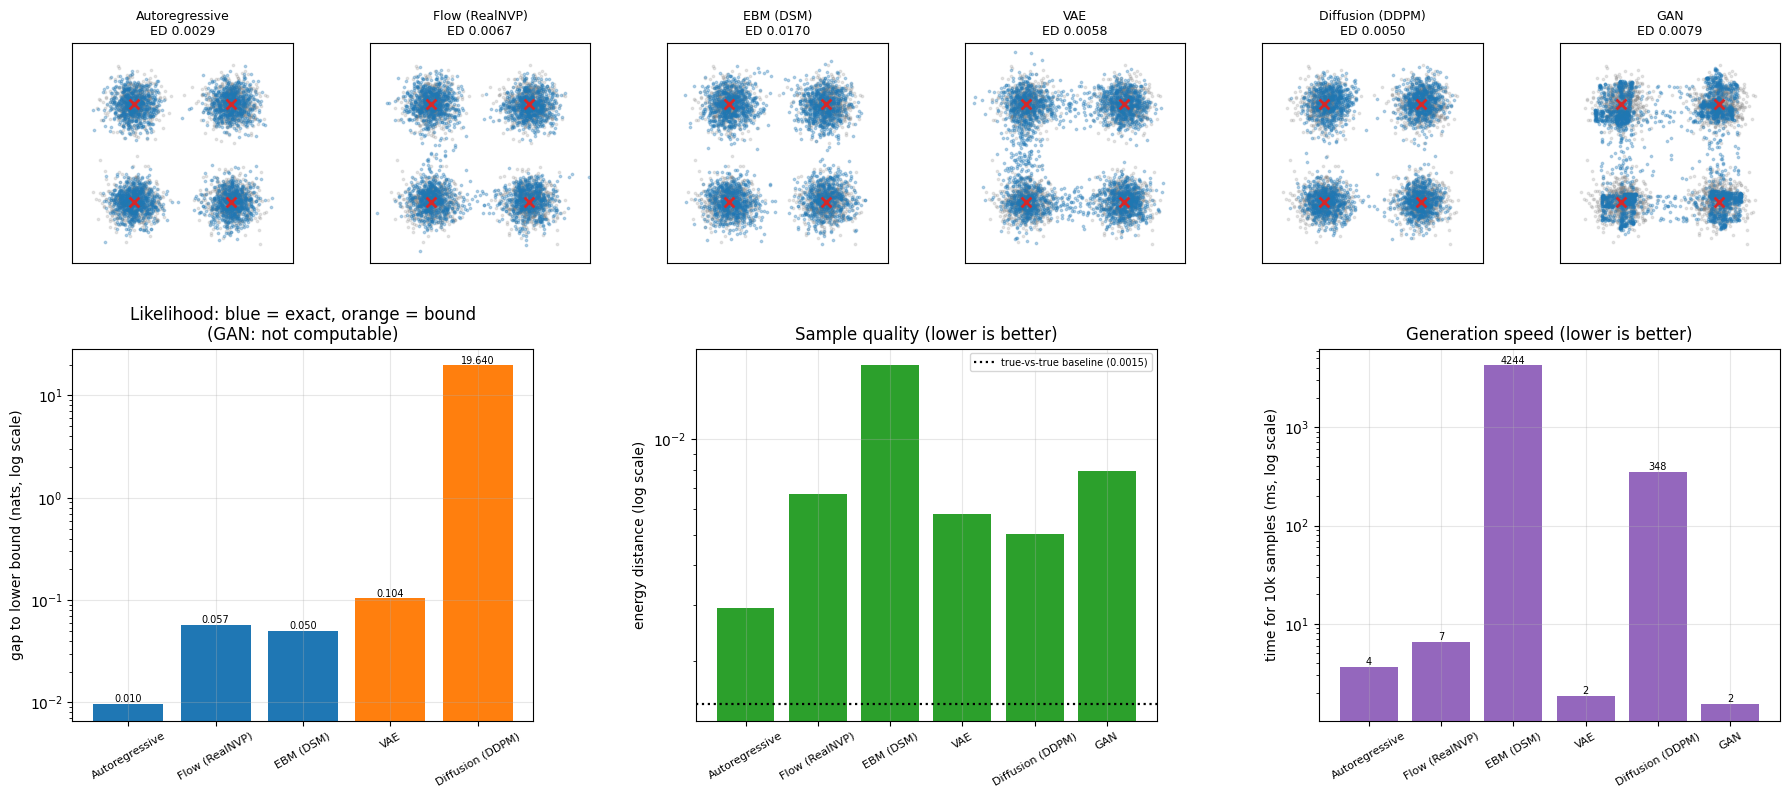

In [11]:
# ============================================================
# 図: 三すくみとサンプル
# ============================================================

fig = plt.figure(figsize=(18, 8.5))
labels_en = {"自己回帰": "Autoregressive", "フロー": "Flow (RealNVP)", "EBM": "EBM (DSM)",
             "VAE": "VAE", "拡散": "Diffusion (DDPM)", "GAN": "GAN"}

# 上段: 各系統のサンプル
for i, k in enumerate(order):
    ax = plt.subplot(2, 6, i + 1)
    s = RESULTS[k]["samples"][:2500].detach().numpy()
    ax.scatter(X_ref[:2500, 0], X_ref[:2500, 1], s=3, alpha=0.18, color="tab:gray")
    ax.scatter(s[:, 0], s[:, 1], s=3, alpha=0.3, color="tab:blue")
    ax.scatter(MODES[:, 0], MODES[:, 1], s=50, marker="x", color="tab:red", lw=2)
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_aspect("equal")
    ax.set_title(f"{labels_en[k]}\nED {RESULTS[k]['ed']:.4f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

# 下段左: 尤度
ax = plt.subplot(2, 3, 4)
ks = [k for k in order if RESULTS[k]["nll"] is not None]
vals = [RESULTS[k]["nll"] - NLL_LB for k in ks]
colors = ["tab:blue" if "厳密" in RESULTS[k]["nll_kind"] else "tab:orange" for k in ks]
ax.bar([labels_en[k] for k in ks], vals, color=colors)
ax.set_yscale("log")
ax.set_ylabel("gap to lower bound (nats, log scale)")
ax.set_title("Likelihood: blue = exact, orange = bound\n(GAN: not computable)")
ax.tick_params(axis="x", labelrotation=30, labelsize=8)
for i, v in enumerate(vals):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7)

# 下段中: サンプル品質
ax = plt.subplot(2, 3, 5)
ax.bar([labels_en[k] for k in order], [RESULTS[k]["ed"] for k in order],
       color="tab:green")
ax.axhline(ED_BASELINE, color="k", ls=":", lw=1.6,
           label=f"true-vs-true baseline ({ED_BASELINE:.4f})")
ax.set_yscale("log")
ax.set_ylabel("energy distance (log scale)")
ax.set_title("Sample quality (lower is better)")
ax.tick_params(axis="x", labelrotation=30, labelsize=8)
ax.legend(fontsize=7)

# 下段右: 生成速度
ax = plt.subplot(2, 3, 6)
ax.bar([labels_en[k] for k in order], [RESULTS[k]["gen"] for k in order],
       color="tab:purple")
ax.set_yscale("log")
ax.set_ylabel("time for 10k samples (ms, log scale)")
ax.set_title("Generation speed (lower is better)")
ax.tick_params(axis="x", labelrotation=30, labelsize=8)
for i, k in enumerate(order):
    ax.text(i, RESULTS[k]["gen"], f"{RESULTS[k]['gen']:.0f}", ha="center",
            va="bottom", fontsize=7)

plt.tight_layout()
plt.show()

<a id="ring"></a>
## 9. モード被覆 — 8峰リングでの比較

4峰は離れていて簡単すぎました。**8峰を円周に並べる**とモード被覆の差が出ます
（GAN のモード崩壊が起きやすい古典的な配置）。

被覆を2つの量で測ります。

| 指標 | 意味 |
|---|---|
| **被覆したモード数** | 占有率 2% 以上のモードの数（0 から 8） |
| **占有率の最大偏差** | 真の 0.125 からのずれ |

「被覆している」と「正しい比率で出している」は別だ、というのが要点です。

In [12]:
# ============================================================
# 8峰リング
# ============================================================

ang = torch.arange(8) * 2 * math.pi / 8
RING = torch.stack([3 * ang.cos(), 3 * ang.sin()], -1)

def sample_ring(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    k = torch.randint(0, 8, (n,), generator=g)
    return RING[k] + 0.25 * torch.randn(n, 2, generator=g)

X_ring = sample_ring(8000, seed=0)
X_ring_ref = sample_ring(10000, seed=2)
print(f"8峰リング: 半径 3、標準偏差 0.25、隣接モード間の距離 "
      f"{float((RING[0]-RING[1]).norm()):.2f} = {float((RING[0]-RING[1]).norm())/0.25:.0f} シグマ")
print()

def ring_report(S):
    occ = torch.bincount(nearest_mode(S, RING), minlength=8).float() / len(S)
    cov = int((occ > 0.02).sum())
    return cov, occ, float((occ - 0.125).abs().max()), energy_distance(S, X_ring_ref)

ring_rows = []

# GAN（4シード）
for sd in [0, 1, 2, 3]:
    g, _ = train_gan(X_ring, steps=8000, seed=sd)
    with torch.no_grad():
        S = g(10000)
    cov, occ, md, ed = ring_report(S)
    ring_rows.append((f"GAN (seed {sd})", cov, md, ed, S))
    print(f"GAN seed={sd}: 被覆 {cov}/8  最大偏差 {md:.3f}  エネルギー距離 {ed:.5f}  "
          f"占有率 {occ.numpy().round(3)}")

# フロー（比較対象）
torch.manual_seed(0)
m_fr = RealNVP(n_layers=8)
opt = torch.optim.Adam(m_fr.parameters(), lr=5e-3)
for _ in range(3000):
    loss = -m_fr.log_prob(X_ring).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
with torch.no_grad():
    S = m_fr.sample(10000)
cov, occ, md, ed = ring_report(S)
ring_rows.append(("フロー", cov, md, ed, S))
print(f"\nフロー: 被覆 {cov}/8  最大偏差 {md:.3f}  エネルギー距離 {ed:.5f}  "
      f"占有率 {occ.numpy().round(3)}")

# 拡散（比較対象）
torch.manual_seed(0)
m_dr = NoisePredictor()
opt = torch.optim.Adam(m_dr.parameters(), lr=2e-3)
for _ in range(8000):
    x = X_ring[torch.randint(0, len(X_ring), (512,))]
    t = torch.randint(0, T, (512,))
    eps = torch.randn_like(x)
    xt = abar[t][:, None].sqrt() * x + (1 - abar[t])[:, None].sqrt() * eps
    loss = ((m_dr(xt, t) - eps) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()

@torch.no_grad()
def ddpm_sample_with(model, n):
    x = torch.randn(n, 2)
    for i in reversed(range(T)):
        t = torch.full((n,), i, dtype=torch.long)
        e = model(x, t)
        mu = (x - betas[i] / (1 - abar[i]).sqrt() * e) / alphas[i].sqrt()
        x = mu + (beta_tilde[i].sqrt() if i > 0 else 0.0) * torch.randn(n, 2)
    return x

S = ddpm_sample_with(m_dr, 10000)
cov, occ, md, ed = ring_report(S)
ring_rows.append(("拡散", cov, md, ed, S))
print(f"拡散  : 被覆 {cov}/8  最大偏差 {md:.3f}  エネルギー距離 {ed:.5f}  "
      f"占有率 {occ.numpy().round(3)}")
print(f"\n真のサンプル同士: エネルギー距離 "
      f"{energy_distance(X_ring_ref, sample_ring(10000, seed=5)):.5f}")

8峰リング: 半径 3、標準偏差 0.25、隣接モード間の距離 2.30 = 9 シグマ



GAN seed=0: 被覆 8/8  最大偏差 0.143  エネルギー距離 0.15956  占有率 [0.245 0.049 0.268 0.05  0.224 0.055 0.059 0.05 ]


GAN seed=1: 被覆 8/8  最大偏差 0.098  エネルギー距離 0.04584  占有率 [0.051 0.202 0.046 0.223 0.043 0.204 0.05  0.181]


GAN seed=2: 被覆 8/8  最大偏差 0.113  エネルギー距離 0.12947  占有率 [0.183 0.04  0.057 0.238 0.216 0.052 0.054 0.161]


GAN seed=3: 被覆 8/8  最大偏差 0.094  エネルギー距離 0.21612  占有率 [0.051 0.219 0.051 0.053 0.054 0.215 0.178 0.179]



フロー: 被覆 8/8  最大偏差 0.014  エネルギー距離 0.00228  占有率 [0.123 0.139 0.123 0.138 0.111 0.117 0.129 0.12 ]


拡散  : 被覆 8/8  最大偏差 0.025  エネルギー距離 0.00585  占有率 [0.1   0.122 0.141 0.136 0.105 0.119 0.147 0.131]

真のサンプル同士: エネルギー距離 0.00150


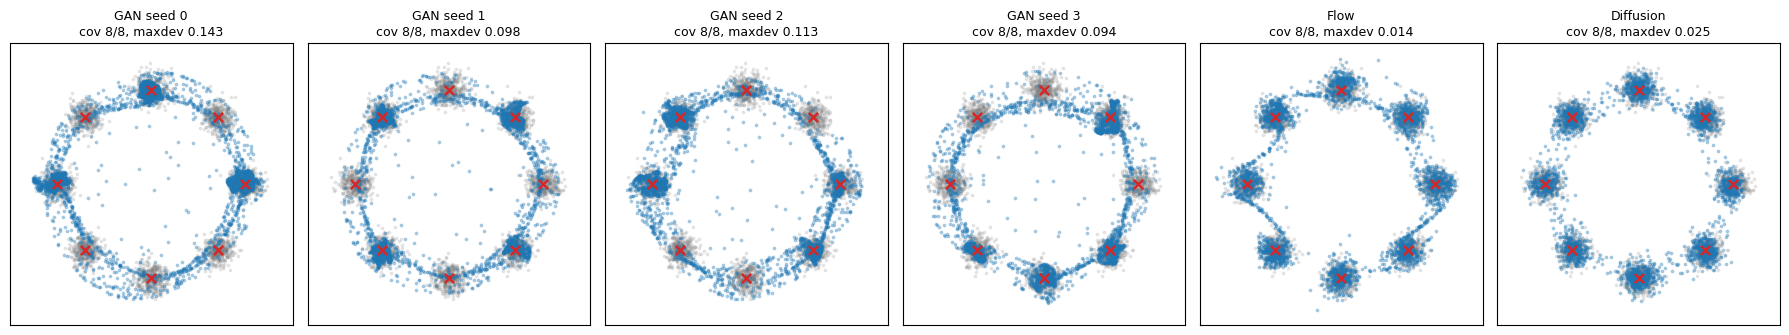

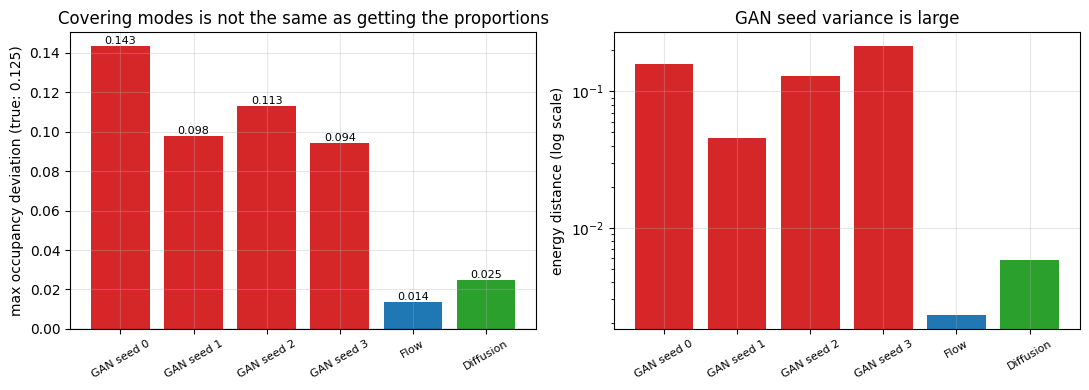

In [13]:
# ============================================================
# 図: 8峰リングでのモード被覆
# ============================================================

fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
labels = ["GAN seed 0", "GAN seed 1", "GAN seed 2", "GAN seed 3", "Flow", "Diffusion"]
for ax, (name, cov, md, ed, S), lab in zip(axes, ring_rows, labels):
    sn = S[:3000].detach().numpy()
    ax.scatter(X_ring_ref[:3000, 0], X_ring_ref[:3000, 1], s=3, alpha=0.15,
               color="tab:gray")
    ax.scatter(sn[:, 0], sn[:, 1], s=3, alpha=0.3, color="tab:blue")
    ax.scatter(RING[:, 0], RING[:, 1], s=45, marker="x", color="tab:red", lw=1.8)
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_aspect("equal")
    ax.set_title(f"{lab}\ncov {cov}/8, maxdev {md:.3f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = [r[0] for r in ring_rows]
axes[0].bar(labels, [r[2] for r in ring_rows],
            color=["tab:red"] * 4 + ["tab:blue", "tab:green"])
axes[0].axhline(0.0, color="k", lw=0.8)
axes[0].set_ylabel("max occupancy deviation (true: 0.125)")
axes[0].set_title("Covering modes is not the same as getting the proportions")
axes[0].tick_params(axis="x", labelrotation=30, labelsize=8)
for i, r in enumerate(ring_rows):
    axes[0].text(i, r[2], f"{r[2]:.3f}", ha="center", va="bottom", fontsize=8)

axes[1].bar(labels, [r[3] for r in ring_rows],
            color=["tab:red"] * 4 + ["tab:blue", "tab:green"])
axes[1].set_yscale("log")
axes[1].set_ylabel("energy distance (log scale)")
axes[1].set_title("GAN seed variance is large")
axes[1].tick_params(axis="x", labelrotation=30, labelsize=8)

plt.tight_layout()
plt.show()

<a id="choose"></a>
## 10. 選び方と、2次元の結果の限界

### 実測の表（下限 2.8275、真のサンプル同士のエネルギー距離 0.00146）

| 系統 | test NLL | 下限との差 | 尤度の種類 | ED | 最大偏差 | 学習 | 生成(1万) |
|---|---|---|---|---|---|---|---|
| 自己回帰 | **2.8372** | **+0.0096** | 厳密 | **0.00294** | 0.0096 | 13s | 4ms |
| EBM | 2.8772 | +0.0496 | 厳密（$Z$ を格子で。2次元限定） | 0.01704 | 0.0292 | 7s | **4244ms** |
| フロー | 2.8844 | +0.0569 | 厳密 | 0.00672 | 0.0137 | 34s | 7ms |
| VAE | 2.9314 | +0.1039 | 下界（ELBO 3.028） | 0.00580 | 0.0090 | 24s | 2ms |
| 拡散 | **22.4678** | +19.6402 | 下界（非常に緩い） | 0.00503 | **0.0068** | 13s | 348ms |
| GAN | — | — | **計算できない** | 0.00791 | 0.0125 | 8s | **2ms** |

3つの順位:

```
尤度       : 自己回帰 < EBM < フロー < VAE < 拡散
サンプル品質 : 自己回帰 < 拡散 < VAE < フロー < GAN < EBM
生成速度    : GAN < VAE < 自己回帰 < フロー < 拡散 < EBM
```

### 予想が外れた点を先に書きます

計画段階で私は「**サンプル品質では拡散が最良**」と書くつもりでした。
実測では **自己回帰が 0.00294 で最小**、拡散は 0.00503 で2位でした。
しかも自己回帰は**尤度でも最良**（+0.0096）です。
つまりこの土俵では**自己回帰が2軸を取っています**。

なぜそうなったか。**2次元だと自己回帰の因子が $p(x_1)p(x_2|x_1)$ の2つだけ**で、
それぞれを混合ガウスで厳密に表せます。制約も近似もありません。
高次元では $d$ 個の因子を逐次生成するので、この有利さは消えます
（$d=196$ なら 196 回の前向き計算）。
**この行は一般化しない結果**として下の表に入れました。

### 用途からの選び方（一般化する部分だけ）

| 用途 | 選ぶべき系統 | 根拠 |
|---|---|---|
| **尤度が必要**（異常検知・圧縮・モデル比較） | 自己回帰 / フロー | 高次元でも厳密な値が出る。EBM は2次元限定 |
| **生成が高速でなければならない** | GAN / VAE / フロー | 1パス。拡散は $T$ 倍（本章で 348ms vs 2ms） |
| **サンプル品質が最優先** | 拡散 | 本章の2次元では自己回帰に負けたが、高次元の画像では拡散が最良とされる（**本章では未検証**） |
| **尤度と品質の両方をある程度** | フロー | 両方で中位。ただし次元を保存するので高次元で重い |
| **学習の安定性** | フロー / 自己回帰 / 拡散 | 尤度ベースで損失が下に有界（195 の議論） |

### 順位が一致しない最も明確な例

**EBM と拡散**です。

| | EBM | 拡散 |
|---|---|---|
| 尤度 | **2位（+0.0496、厳密）** | **最下位（下界 22.47）** |
| サンプル品質 | **最下位（0.01704）** | **2位（0.00503）** |
| 生成速度 | **最下位（4244ms）** | 5位（348ms） |

EBM は尤度で2位なのに、サンプル品質と速度では最下位です。
原因はサンプリングがランジュバン 1000 ステップだからで、194 で測った困難
（混合しない・ステップ数を払う必要がある）がそのまま出ています。
拡散は逆で、下界は壊滅的なのにサンプルは良い。

191 第7節でも同じことを見ました（bits/dim 2.6552 なのにサンプルが数字に見えない）。
**この2つは別の誤りを測っています。**

- 尤度 $\mathbb{E}_{p_{\text{data}}}[\log p_\theta]$ は「**データを見逃す誤り**」に厳しい
- サンプル品質は「**余計な場所に確率を置く誤り**」に厳しい

前者は $\mathrm{KL}(p_{\text{data}} \| p_\theta)$、後者は逆向きの
$\mathrm{KL}(p_\theta \| p_{\text{data}})$ に対応します。
**どちらを最小化しているかで、どちらの誤りに甘いかが決まります。**

### 2次元の結果のうち、何が一般化しないか

本章は2次元なので、以下は**そのまま一般化しません**。

| 本章の結果 | 高次元では |
|---|---|
| EBM の NLL が出せた | **出せない**（193: $d=5$ で格子不能、$d=40$ で重点サンプリング崩壊） |
| GAN が4峰を取りこぼさなかった | 高次元ではモード崩壊が深刻な問題になる |
| **自己回帰が尤度もサンプル品質も最良** | 2次元だと因子が2つだけで厳密に表せる。$d$ 因子の逐次生成になると**$d$ に比例して遅く**、誤差も累積する |
| 自己回帰の生成が 4ms | $d$ 回の逐次前向き計算になる |
| フローのパラメータ数が小さい | 次元を保存するので高次元で重い（191: $d=196$ で 174万） |
| 拡散の生成が 353ms | 高次元でも $T$ 回の前向き計算。相対的な遅さは変わらない |

一般化するのは**構造的な性質**だけです。

| 一般化する | 理由 |
|---|---|
| 尤度を厳密に出せるのは自己回帰・フローだけ | 正規化の扱いが構造で決まっている |
| 拡散の生成は $T$ 倍遅い | 逐次性は次元に依らない |
| GAN は尤度を持たない | 定義上そう |
| 尤度と品質の順位が一致しない | 最小化している発散が違う |
| 下に有界な損失は崩壊しない | 195 で測った構造的な性質 |

### Unit 17 全体のまとめ

| 章 | 到達点 |
|---|---|
| 190 | 変数変換の公式を数値検証。$Z$ でなく行列式が壁 |
| 191 | カップリング層で3条件を同時に満たす。$d=196$ で 2.6552 bits/dim |
| 193 | $Z$ の壁を実測（$d=40$ で有効サンプル数 1.5）。スコアは $Z$ なしで出る |
| 194 | スコアだけでサンプル。集計統計の罠。CD の崩壊（$4.4\times10^9$） |
| 195 | ノイズ予測＝スコア学習を係数込みで検証。拡散が EBM の解になっている |
| **196** | **6系統を同じ土俵で測り、三すくみを数で示した** |

<a id="quiz"></a>
## 11. 自己評価クイズ

### Q1: 拡散モデルの下界が緩い理由

**問題**: 本章の拡散モデルはサンプル品質が最良でしたが、変分下界は
到達可能な下限から大きく離れていました。内訳を見ると中間の KL の和が支配的でした。
なぜこの項が大きくなるのか、そして**なぜそれが問題にならないのか**を説明してください。

<details>
<summary>答えを見る</summary>

**大きくなる理由**: 中間の KL 項は

$$L_{t-1} = \frac{\|\tilde\mu_t - \mu_\theta(x_t,t)\|^2}{2\tilde\beta_t}$$

で、分母の $\tilde\beta_t$ が**小さい $t$ で極端に小さい**です。
本章の実測では $\tilde\beta_1 \approx 5\times10^{-5}$ なので、重みが約1万倍になります。
ノイズ予測のわずかな誤差が、下界では巨大な値に増幅されます。

**問題にならない理由**: **本モデルは下界を最適化していません。**
学習に使ったのは簡略化損失

$$\mathcal{L}_{\text{simple}} = \mathbb{E}\|\epsilon - \epsilon_\theta(x_t,t)\|^2$$

で、$1/(2\tilde\beta_t)$ の重みを**外した**ものです。
つまり小さい $t$（ほぼノイズのない領域）を相対的に軽視し、
大きい $t$（構造を決める領域）を重視しています。
これが DDPM 原論文が簡略化損失を採用した理由で、
**サンプル品質は上がるが下界は悪くなる**というトレードオフを意図的に選んでいます。

したがって本章の下界の値は「このモデルの尤度が悪い」ことの証拠ではなく、
「**下界が尤度の良い推定になっていない**」ことの証拠です。
拡散モデルの尤度を真面目に評価するには連続時間（確率流 ODE）の定式化が必要で、
本章の範囲外です。
</details>

---

### Q2: ELBO の緩みの意味

**問題**: 本章の VAE は ELBO と IWAE 推定の差が測れました。
この差が小さいとき、何が言えますか。また差が小さいことは「VAE が良い」ことを
意味しますか。

<details>
<summary>答えを見る</summary>

ELBO と $\log p(x)$ の差は**厳密に** $D_{\mathrm{KL}}(q(z|x)\,\|\,p(z|x))$ です。

$$\log p(x) - \text{ELBO} = D_{\mathrm{KL}}\big(q(z|x)\,\|\,p(z|x)\big)$$

差が小さいとは「**近似事後分布が真の事後分布に近い**」ということで、
推論ネットワーク（エンコーダ）の質を測っています。

**「VAE が良い」ことは意味しません。** 差が小さくても $\log p(x)$ 自体が
下限から遠ければ、モデルは悪いままです。本章の実測でも、
ELBO の緩みは小さいのに IWAE 推定は下限からそれなりに離れています。

2つを混同しないことが重要です。

| 量 | 測っているもの |
|---|---|
| $\log p(x)$ の下限からの差 | **モデルの質**（生成モデルとしての性能） |
| ELBO と $\log p(x)$ の差 | **推論の質**（エンコーダの近似精度） |

ELBO だけ報告すると、この2つが混ざった数字になります。
IWAE で分離するのが誠実な報告です。
</details>

---

### Q3: 順位が一致しないことの意味

**問題**: 本章で尤度の順位・サンプル品質の順位・生成速度の順位が一致しませんでした。
これは「測り方が悪い」のでしょうか。

<details>
<summary>答えを見る</summary>

測り方の問題ではなく、**3つが本質的に別の量**だからです。

- 尤度は $\mathrm{KL}(p_{\text{data}} \| p_\theta)$ の最小化に対応し、
  **$p_\theta$ が $p_{\text{data}}$ を覆っていないこと**に厳しい（mode-covering）。
  余計な場所に確率を置いても大して罰されません。
- サンプル品質（人間の評価や、本章のエネルギー距離）は
  逆向き $\mathrm{KL}(p_\theta \| p_{\text{data}})$ に近い感度を持ち、
  **データのない場所に確率を置くこと**に厳しい（mode-seeking）。
- 生成速度はアーキテクチャの逐次性で決まり、分布の良さと無関係です。

したがって「総合的に最良の生成モデル」は**定義できません**。
用途が決まって初めて順位が決まります。

実務上の含意として、**論文の数字を1つだけ見て判断してはいけない**ことが導かれます。
bits/dim が良い報告はサンプルが汚い可能性があり、
サンプルが美しい報告は尤度が悪い（またはそもそも測っていない）可能性があります。
本章の表のように**3軸を並べて初めて比較になります**。
</details>

---

### Q4: 8峰リングで何が分かったか

**問題**: 8峰リングで GAN は「全モードを被覆したが占有率が偏った」結果になりました。
「被覆率」だけを報告する評価の問題点を述べてください。

<details>
<summary>答えを見る</summary>

被覆率は「そのモードにサンプルが**1つでもあるか**」しか見ません。
真の比率 0.125 に対して 0.04 と 0.27 が混じっていても、
被覆率は 8/8 で**満点**になります。

本章の実測では、GAN は4シードすべてで 8/8 を被覆しましたが、
占有率の最大偏差は大きく、シード間のばらつきも大きかったです。
「モード崩壊していない」と「分布が合っている」は別です。

必要な指標は少なくとも2つです。

| 指標 | 見るもの |
|---|---|
| 被覆率 | **完全な取りこぼし**（確率 0 の領域） |
| 占有率の偏差 / 分布距離 | **比率の誤り** |

これは 194 第4節の教訓（集計統計が初期値の対称性で嘘をつく）と同じ型です。
**1つの要約統計量で分布の一致を主張してはいけません。**

さらに本章では、GAN のエネルギー距離がシード間で大きくばらつきました。
**単一シードの GAN の結果は、良くても悪くても信用できません。**
</details>

In [14]:
# ============================================================
# 最終サマリ
# ============================================================

def fmt_row(k):
    r = RESULTS[k]
    nll_s = "—".rjust(10) if r["nll"] is None else f"{r['nll']:10.4f}"
    return (f"  {k:<6}: NLL {nll_s}  ED {r['ed']:.5f}  最大偏差 {r['md']:.4f}"
            f"  学習 {r['train']:4.0f}s  生成 {r['gen']:6.0f}ms  [{r['nll_kind']}]")

lines_models = "\n".join(fmt_row(k) for k in order)
lines_vae = " / ".join(
    f"zd={r[0]}: ELBO {r[1]:.4f} IWAE {r[2]:.4f} 緩み {r[3]:.4f}" for r in vae_rows)
lines_ring = "\n".join(
    f"  {r[0]:<16}: 被覆 {r[1]}/8  占有率の最大偏差 {r[2]:.3f}  エネルギー距離 {r[3]:.5f}"
    for r in ring_rows)
w_small_t = 1.0 / (2 * float(beta_tilde[1]))

print("=" * 80)
print("Notebook 196 完了: 生成モデル6系統の総括")
print("=" * 80)
print(f"""
【共通の土俵】2次元4峰混合ガウス。到達可能な NLL の下限 {NLL_LB:.4f}
  基準（真のサンプル同士）: エネルギー距離 {ED_BASELINE:.5f}  占有率の最大偏差 {MD_BASELINE:.4f}

【6系統の実測】
{lines_models}

  尤度の順位       : {" < ".join(by_nll)}
  サンプル品質の順位 : {" < ".join(by_ed)}
  生成速度の順位    : {" < ".join(by_gen)}
  -> 3つの順位が一致しない。これが三すくみ。

【VAE の ELBO の緩み】
  {lines_vae}
  -> 「下界」の緩さを数で言える。ELBO と log p の差は KL(q(z|x) || p(z|x)) そのもの。

【拡散の変分下界の内訳】
  L_T {bound_parts['L_T']:.4f} / L_0 {bound_parts['L_0']:.4f} / 中間の KL の和 {bound_parts['KL_sum']:.4f}
  -> 中間の KL が支配的。1/(2*beta_tilde_t) の重みが小さい t で約 {w_small_t:.0f} 倍になる。
     DDPM が簡略化損失（重みを外した二乗誤差）で学習するのはこのため。
     本モデルは下界を最適化していない。下界は評価にだけ使った。

【8峰リングでのモード被覆】
{lines_ring}
  -> 被覆率は満点でも占有率は偏る。「被覆」と「比率が合う」は別。
     GAN のシード間のばらつきも大きい（単一シードの結果は信用できない）。

【一般化すること / しないこと】
  一般化する: 厳密尤度を出せるのは自己回帰とフローだけ / 拡散の生成は T 倍遅い /
              GAN は尤度を持たない / 尤度と品質の順位は一致しない /
              下に有界な損失は崩壊しない
  しない    : EBM の NLL が出せた（2次元限定）/ GAN がモードを取りこぼさなかった /
              自己回帰が速い（因子が2つだけ）/ フローが軽い（次元を保存するので高次元で重い）

【Unit 17 完了】190 → 191 → 193 → 194 → 195 → 196
""")
print("=" * 80)

Notebook 196 完了: 生成モデル6系統の総括

【共通の土俵】2次元4峰混合ガウス。到達可能な NLL の下限 2.8275
  基準（真のサンプル同士）: エネルギー距離 0.00146  占有率の最大偏差 0.0073

【6系統の実測】
  自己回帰  : NLL     2.8372  ED 0.00294  最大偏差 0.0096  学習   13s  生成      4ms  [厳密]
  フロー   : NLL     2.8844  ED 0.00672  最大偏差 0.0137  学習   34s  生成      7ms  [厳密]
  EBM   : NLL     2.8772  ED 0.01704  最大偏差 0.0292  学習    7s  生成   4244ms  [厳密（ただし Z を格子で計算。2次元限定）]
  VAE   : NLL     2.9314  ED 0.00580  最大偏差 0.0090  学習   24s  生成      2ms  [下界（IWAE 推定、ELBO 3.028）]
  拡散    : NLL    22.4678  ED 0.00503  最大偏差 0.0068  学習   13s  生成    348ms  [下界（変分下界。非常に緩い）]
  GAN   : NLL          —  ED 0.00791  最大偏差 0.0125  学習    8s  生成      2ms  [計算できない]

  尤度の順位       : 自己回帰 < EBM < フロー < VAE < 拡散
  サンプル品質の順位 : 自己回帰 < 拡散 < VAE < フロー < GAN < EBM
  生成速度の順位    : GAN < VAE < 自己回帰 < フロー < 拡散 < EBM
  -> 3つの順位が一致しない。これが三すくみ。

【VAE の ELBO の緩み】
  zd=1: ELBO 3.0275 IWAE 2.9314 緩み 0.0961 / zd=2: ELBO 3.5881 IWAE 3.5826 緩み 0.0055 / zd=4: ELBO 3.0127 IWAE 2.9341 緩み 0.0785
  -> 「下界」の緩さを数で言える。ELBO と log 